In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_classes= 2,
    n_features=2,
    n_redundant= 0,
    random_state=42,
    n_clusters_per_class=1,
    n_informative=2,
    class_sep=2
)

In [3]:
print(type(X))
print(type(y))
print(X.shape)
print(y.shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(1000, 2)
(1000,)


In [4]:
df = pd.DataFrame(X, columns=['f1', 'f2'])
df['Target'] = y
df.head()

,f1,f2,Target
0,1.601034,2.535353,1
1,1.755945,-2.172352,0
2,2.354479,-1.948528,0
3,4.103090,-0.766515,0
4,1.753178,1.787514,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f1      1000 non-null   float64
 1   f2      1000 non-null   float64
 2   Target  1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


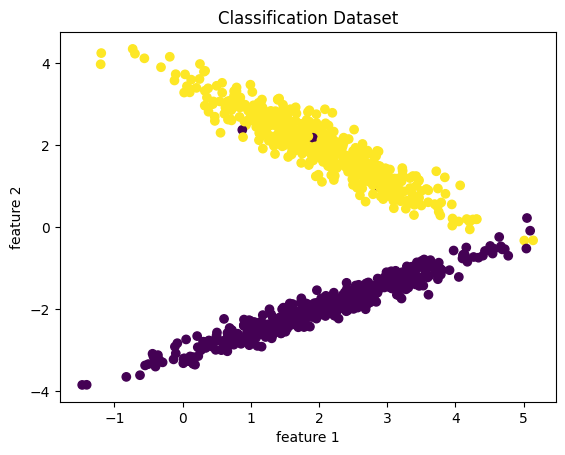

In [6]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y)

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Classification Dataset")

plt.show()

In [7]:
assigned_centroid = [-1 for i in range(1000)]

In [8]:
u1 = [2, 0]
u2 = [2, 5]

In [9]:
for i in range(1000):

    for i in range(1000):
        dist_u1 = (u1[0]-X[i][0])**2 + (u1[1] - X[i][1])**2
        dist_u2 = (u2[0]-X[i][0])**2 + (u2[1] - X[i][1])**2

        if dist_u1 < dist_u2:
            assigned_centroid[i] = 0
        else:
            assigned_centroid[i] = 1

    c0_f1_sum = 0
    c1_f1_sum = 0
    c0_f2_sum = 0
    c1_f2_sum = 0

    c0_cnt = 0
    c1_cnt = 0
    for i in range(1000):
        if assigned_centroid[i] == 0:
            c0_cnt += 1
            c0_f1_sum += X[i][0]
            c0_f2_sum += X[i][1]
        else:
            c1_cnt += 1
            c1_f1_sum += X[i][0]
            c1_f2_sum += X[i][1]

    if c0_cnt != 0:
        u1[0] = c0_f1_sum/c0_cnt
        u1[1] = c0_f2_sum/c0_cnt

    if c1_cnt != 0:
        u2[0] = c1_f1_sum/(c1_cnt)
        u2[1] = c1_f2_sum/(c1_cnt)


In [10]:
u1

[np.float64(2.033367439774086), np.float64(-1.975972052264301)]

In [11]:
u2

[np.float64(2.0182816377527004), np.float64(1.9584546979747144)]

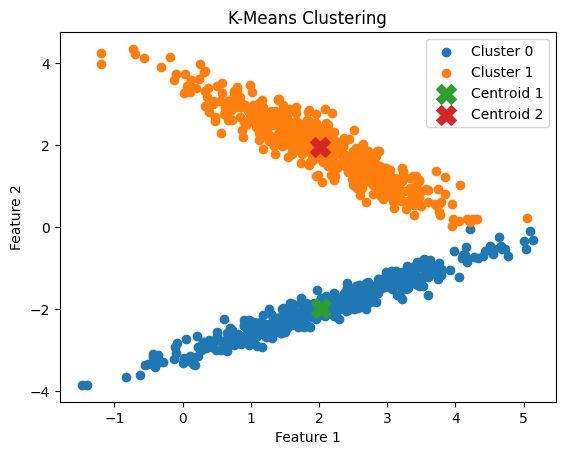

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Convert assignments to NumPy array
assigned_centroid = np.array(assigned_centroid)

# Plot the actual data points
plt.scatter(
    X[assigned_centroid == 0, 0],
    X[assigned_centroid == 0, 1],
    label="Cluster 0"
)

plt.scatter(
    X[assigned_centroid == 1, 0],
    X[assigned_centroid == 1, 1],
    label="Cluster 1"
)

# Plot centroids
plt.scatter(
    u1[0], u1[1],
    marker="X",
    s=200,
    label="Centroid 1"
)

plt.scatter(
    u2[0], u2[1],
    marker="X",
    s=200,
    label="Centroid 2"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

### GENERALISED K_MEANS CLUSTERING

In [13]:
def kmeansFit(X, k = 2, max_iters=100):
    n_samples, n_features = X.shape

    random_indices = np.random.choice(n_samples, size=k, replace=False)
    centroids = X[random_indices].copy()

    assigned_centroid = np.zeros(n_samples)

    for iteration in range(max_iters):
        dist = np.zeros((n_samples, k))
        for j in range(k):
            dist[:, j] = np.sum((X-centroids[j])**2, axis = 1)

        new_assignments = np.argmin(dist, axis = 1)

        if np.array_equal(assigned_centroid, new_assignments):
            print(f"Converged on iteration {iteration}")
            break

        assigned_centroid = new_assignments

        for j in range(k):
            cluster_points = X[assigned_centroid == j]

            if len(cluster_points) > 0:
                centroids[j] = np.mean(cluster_points, axis = 0)

    return assigned_centroid, centroids


Converged on iteration 8


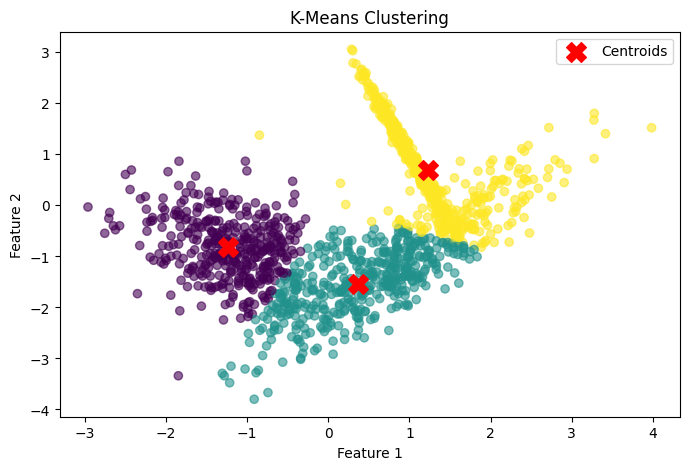

In [14]:
X, y_true = make_classification(
    n_samples=1500, n_classes=3, n_features=2,
    n_redundant=0, random_state=42, n_clusters_per_class=1
)

assignments, final_centroids = kmeansFit(X, k=3, max_iters=100)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=assignments, cmap='viridis', alpha=0.6)
plt.scatter(final_centroids[:, 0], final_centroids[:, 1],
            marker="X", s=200, c='red', label="Centroids")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

### WCSS

Converged on iteration 0
Converged on iteration 10
Converged on iteration 31
Converged on iteration 26
Converged on iteration 45
Converged on iteration 14
Converged on iteration 17
Converged on iteration 27
Converged on iteration 22
Converged on iteration 19


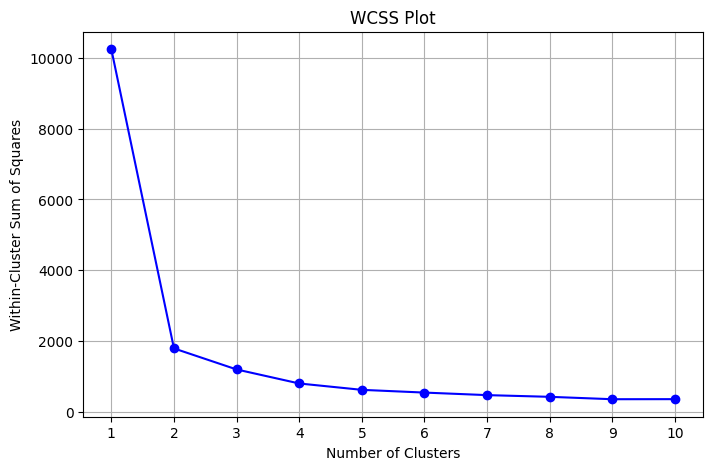

In [15]:
import matplotlib.pyplot as plt
import numpy as np

def calculate_inertia(X, centroids, assignments):
    inertia = 0
    k = len(centroids)
    for j in range(k):
        cluster_points = X[assignments == j]
        if len(cluster_points) > 0:
            inertia += np.sum((cluster_points - centroids[j]) ** 2)
    return inertia

k_values = range(1, 11)
inertias = []

for k in k_values:
    assignments, centroids = kmeansFit(X, k=k, max_iters=100)

    current_inertia = calculate_inertia(X, centroids, assignments)
    inertias.append(current_inertia)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Clusters')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('WCSS Plot')
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Kaggle Dataset

In [17]:
df = pd.read_csv('/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [19]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [20]:
df.drop(columns=['CustomerID'], inplace=True)

In [21]:
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [22]:
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [23]:
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit_transform(df)
X = df.values

Converged on iteration 2


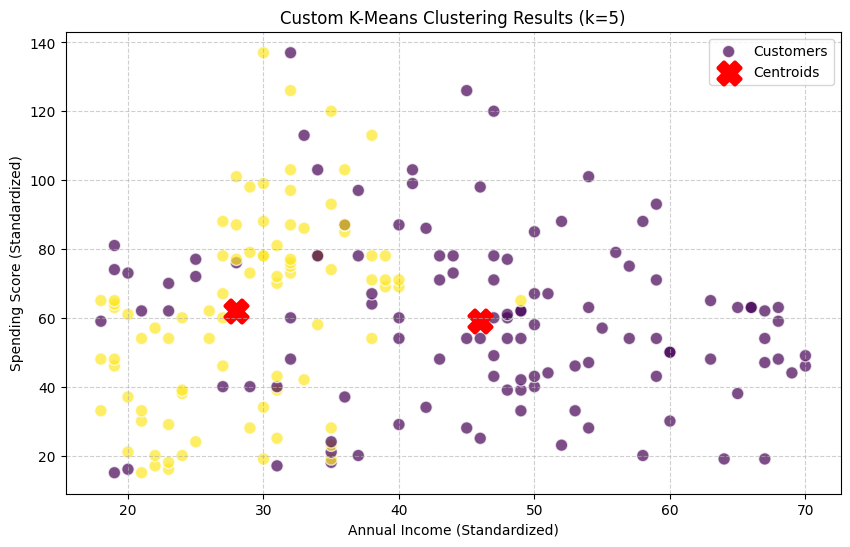

In [25]:
labels, centroids = kmeansFit(X, k=2)

plt.figure(figsize=(10, 6))

plt.scatter(
    X[:, 1],
    X[:, 2],
    c=labels,
    cmap='viridis',
    alpha=0.7,
    edgecolors='w',
    s=80,
    label='Customers'
)

plt.scatter(
    centroids[:, 1],
    centroids[:, 2],
    c='red',
    marker='X',
    s=250,
    linewidths=3,
    label='Centroids'
)

plt.title('Custom K-Means Clustering Results (k=5)')
plt.xlabel('Annual Income (Standardized)')
plt.ylabel('Spending Score (Standardized)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Converged on iteration 0
Converged on iteration 7
Converged on iteration 9
Converged on iteration 11
Converged on iteration 12
Converged on iteration 4
Converged on iteration 5
Converged on iteration 5
Converged on iteration 6
Converged on iteration 5


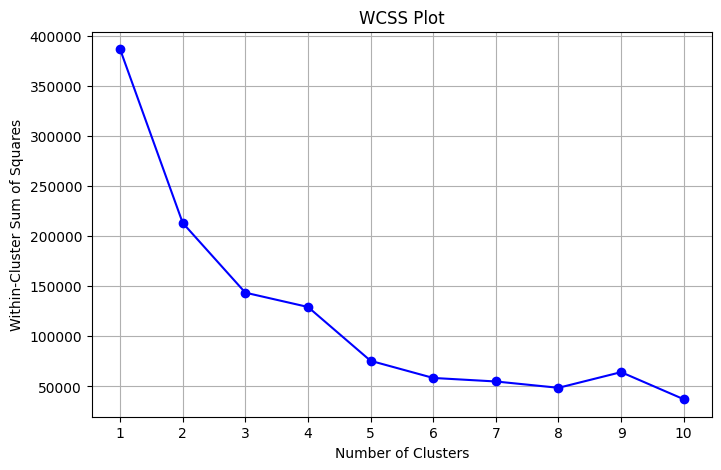

In [26]:
import matplotlib.pyplot as plt
import numpy as np

def calculate_inertia(X, centroids, assignments):
    inertia = 0
    k = len(centroids)
    for j in range(k):
        cluster_points = X[assignments == j]
        if len(cluster_points) > 0:
            inertia += np.sum((cluster_points - centroids[j]) ** 2)
    return inertia

k_values = range(1, 11)
inertias = []

for k in k_values:
    assignments, centroids = kmeansFit(X, k=k, max_iters=100)

    current_inertia = calculate_inertia(X, centroids, assignments)
    inertias.append(current_inertia)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Clusters')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('WCSS Plot')
plt.xticks(k_values)
plt.grid(True)
plt.show()